In [1]:
import pandas as pd

pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
pd.set_option("max_colwidth", 200)

import seaborn as sns
import numpy as np
from matplotlib import pyplot as plt
import os.path
import fuzzywuzzy as fz
import googletrans as gtr
import translate as tr
import langdetect as ld
os.getcwd()

'.'

In [2]:
# df3 = pd.read_csv('en_openfoodfacts_org_products_V3.csv',encoding ='utf-8')

df3 = pd.read_csv('en_openfoodfacts_org_products_V3.csv')


In [39]:
df3.head()

,Unnamed: 0,code,url,product_name,generic_name,quantity,brands,categories,manufacturing_places,labels,emb_codes,purchase_places,stores,countries,ingredients_text,allergens,traces_tags,serving_size,nutriscore_score,nutriscore_grade,pnns_groups_1,pnns_groups_2,states,brand_owner,ecoscore_score_fr,ecoscore_grade_fr,main_category,image_url,image_ingredients_url,image_nutrition_url,nutrition-score-fr_100g,energy-kcal_100g,energy_100g,fat_100g,carbohydrates_100g,sugars_100g,proteins_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,potassium_100g,calcium_100g,polyunsaturated-fat_100g,vitamin-e_100g,vitamin-b1_100g,vitamin-b2_100g,vitamin-b6_100g,vitamin-b12_100g,magnesium_100g
0,5,0000000000100,http://world-en.openfoodfacts.org/product/0000000000100/moutarde-au-mout-de-raisin-courte-paille,moutarde au moût de raisin,NaN,100g,courte paille,"Epicerie, Condiments, Sauces, Moutardes",NaN,Delois france,NaN,NaN,courte paille,France,eau graines de téguments de moutarde vinaigre de vin rouge sel vin rouge sucre moût de raisin (6.2%) oignons colorants extraits de carotte et extrait de paprika huile de tournesol son de moutard...,en:mustard,NaN,NaN,18.0,d,Fat and sauces,Dressings and sauces,"en:to-be-completed, en:nutrition-facts-completed, en:ingredients-completed, en:expiration-date-completed, en:characteristics-to-be-completed, en:packaging-to-be-completed, en:photos-to-be-validate...",NaN,60.0,b,en:mustards,https://static.openfoodfacts.org/images/products/000/000/000/0100/front.3.400.jpg,NaN,NaN,18.0,0.0,936.0,8.2,29.0,22.0,5.1,1.8400,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,16,0000000000949,http://world-en.openfoodfacts.org/product/0000000000949/salade-de-carottes-rapees,Salade de carottes râpées,NaN,NaN,NaN,"Plats préparés, Légumes préparés, Carottes râpées, Carottes râpées assaisonnées",NaN,NaN,NaN,NaN,NaN,France,NaN,NaN,NaN,NaN,1.0,b,Composite foods,One-dish meals,"en:to-be-completed, en:nutrition-facts-completed, en:ingredients-to-be-completed, en:expiration-date-to-be-completed, en:packaging-code-to-be-completed, en:characteristics-to-be-completed, en:cate...",NaN,83.0,b,en:seasoned-shredded-carrots,https://static.openfoodfacts.org/images/products/000/000/000/0949/front_fr.4.400.jpg,https://static.openfoodfacts.org/images/products/000/000/000/0949/ingredients_fr.10.400.jpg,NaN,1.0,32.0,134.0,0.3,5.3,3.9,0.9,0.1680,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,24,0000000001199,http://world-en.openfoodfacts.org/product/0000000001199/solene-cereales-poulet-crous,Solène céréales poulet,NaN,NaN,CROUS,NaN,NaN,NaN,NaN,NaN,NaN,France,"antioxydant : érythorbate de sodium, colorant : caramel - origine UE), tomate 33,3%, MAYONNAISE 11,1% (huile de colza 78,9%, eau, jaunes d'OEUF 6%, vinaigre, MOUTARDE [eau, graines de MOUTARDE, se...","en:eggs,en:mustard",NaN,NaN,NaN,NaN,unknown,unknown,"en:to-be-completed, en:nutrition-facts-completed, en:ingredients-to-be-completed, en:expiration-date-to-be-completed, en:packaging-code-to-be-completed, en:characteristics-to-be-completed, en:cate...",NaN,NaN,NaN,NaN,https://static.openfoodfacts.org/images/products/000/000/000/1199/front_fr.13.400.jpg,https://static.openfoodfacts.org/images/products/000/000/000/1199/ingredients_fr.17.400.jpg,https://static.openfoodfacts.org/images/products/000/000/000/1199/nutrition_fr.14.400.jpg,NaN,219.0,916.0,5.9,30.3,1.7,9.7,0.1856,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,25,0000000001281,http://world-en.openfoodfacts.org/product/0000000001281/tarte-noix-de-coco-crous-resto,Tarte noix de coco,NaN,NaN,"Crous Resto',Crous","Tartes, Tartes sucrées, Tartes à la noix de coco",NaN,NaN,NaN,NaN,NaN,France,NaN,NaN,NaN,NaN,14.0,d,Sugary snacks,Biscuits and cakes,"en:to-be-completed, en:nutrition-facts-completed, en:ingredients-to-be-completed, en:expiration-date-to-be-completed, en:packaging-code-to-be-completed, en:characteristics-to-be-completed, en:cate...",NaN,NaN,NaN,en:coconut-pies,https://static.openfoodfacts.org/images/products/000/000/000/1281/front_fr.11.400.jpg,htt

not used here.

from translate import Translator
from langdetect import detect


#translator= Translator(to_lang="fr")
#translation = translator.translate("bu bir kalem.",from_lang=detect('bu bir kalem'),to_lang="fr")

#print(detect('Aceite de oliva virgen extra'))

from googletrans import Translator
translator = Translator()
print(translator.translate('bu bir kalem',dest='fr').text)


#df3.dtypes
#df3.head()

In [3]:
df3.rename(columns={"Unnamed: 0":"Ancien_Index"},inplace=True)


In [68]:
# done in the previous notebook, except for 'main category'.

# Replace NaN values of ['energy_100g','fat_100g','carbohydrates_100g','sugars_100g','proteins_100g','sodium_100g'] with 0

#liste_to_0=['energy_100g','fat_100g','carbohydrates_100g','sugars_100g','proteins_100g','sodium_100g']

# df3[liste_to_0] = df3[liste_to_0].replace({np.nan:0})
# df3['main_category'] = df3['main_category'].replace({np.nan:'-'})    #refaire tourner si beug

#df5.insert(4,'product_brand',df5['product_name']+', '+df5['brands'],True)

#df["City_English"] = df["City_trad_chinese"].map(lambda x: translator.translate(x, src="zh-TW", dest="en").text)

#df3.head()

In [4]:
# df3["Unnamedian: 0"] = df3["Unnamedian: 0"].astype('unicode')
# df3["product_name"] = df3.product_name.astype(str)



df3["Ancien_Index"] = df3["Ancien_Index"].astype('unicode')
df3["Ancien_Index"] = df3.Ancien_Index.astype(int)

df3["url"] = df3.url.astype(str)
df3["product_name"] = df3.product_name.astype(str)

df3["generic_name"] = df3["generic_name"].astype('unicode')
df3["generic_name"] = df3.generic_name.astype(str)

df3["quantity"] = df3.quantity.astype(str)
df3["brands"] = df3.brands.astype(str)
df3["categories"] = df3.categories.astype(str)
df3["manufacturing_places"] = df3.manufacturing_places.astype(str)
df3["labels"] = df3.labels.astype(str)
df3["purchase_places"] = df3.purchase_places.astype(str)

df3["stores"] = df3.stores.astype(str)
df3["ingredients_text"] = df3.ingredients_text.astype(str)
df3["traces_tags"] = df3.traces_tags.astype(str)
df3["serving_size"] = df3.serving_size.astype(str)
df3["nutriscore_grade"] = df3.nutriscore_grade.astype(str)
df3["states"] = df3.states.astype(str)
df3["brand_owner"] = df3.brand_owner.astype(str)
df3["ecoscore_grade_fr"] = df3.ecoscore_grade_fr.astype(str)
df3["main_category"] = df3.main_category.astype(str)
df3["image_url"] = df3.image_url.astype(str)
df3["image_ingredients_url"] = df3.image_ingredients_url.astype(str)
df3["image_nutrition_url"] = df3.image_nutrition_url.astype(str)

df3["pnns_groups_2"]=df3.pnns_groups_2.astype(str)
df3["pnns_groups_1"]=df3.pnns_groups_1.astype(str)


In [5]:
# df3["code"] = df3.code.astype(float)

df3.dtypes

Ancien_Index                  int32
code                         object
url                          object
product_name                 object
generic_name                 object
quantity                     object
brands                       object
categories                   object
manufacturing_places         object
labels                       object
emb_codes                    object
purchase_places              object
stores                       object
countries                    object
ingredients_text             object
allergens                    object
traces_tags                  object
serving_size                 object
nutriscore_score            float64
nutriscore_grade             object
pnns_groups_1                object
pnns_groups_2                object
states                       object
brand_owner                  object
ecoscore_score_fr           float64
ecoscore_grade_fr            object
main_category                object
image_url                   

# no need to remove duplicates on code: very few of them

d = {'Ancien_Index':'first',
    'url':'first',
 'product_name':'first',
 'generic_name':'first',
 'quantity':'first',
 'brands':'first',
 'categories':'first',
 'manufacturing_places':'first',
 'labels':'first',
 'emb_codes':'first',
 'purchase_places':'first',
 'stores':'first',
 'countries':'first',
 'ingredients_text':'first',
 'allergens':'first',
 'traces_tags':'first',
 'serving_size':'first',
 'nutriscore_score':'mean',
 'nutriscore_grade':'first',
 'states':'first',
 'brand_owner':'first',
 'ecoscore_score_fr':'mean',
 'ecoscore_grade_fr':'first',
 'main_category':'first',
 'image_url':'first',
 'image_ingredients_url':'first',
 'image_nutrition_url':'first',
 'energy-kcal_100g':'mean',
 'energy_100g':'mean',
 'fat_100g':'mean',
 'carbohydrates_100g':'mean',
 'sugars_100g':'mean',
 'proteins_100g':'mean',
 'sodium_100g':'mean',
 'vitamin-a_100g':'mean',
 'vitamin-c_100g':'mean',
 'potassium_100g':'mean',
 'calcium_100g':'mean',
 'nutrition-score-fr_100g':'mean',
 'polyunsaturated-fat_100g':'mean',
 'vitamin-e_100g':'mean',
 'vitamin-b1_100g':'mean',
 'vitamin-b2_100g':'mean',
 'vitamin-b6_100g':'mean',
 'vitamin-b12_100g':'mean',
 'magnesium_100g':'mean'}

df4 = (df3.groupby(['code'], sort=False, as_index=False).agg(d).reindex(columns=df3.columns))

#df['text'].str.len()
#df[df['A'].isin([5.3, 2.7])]

# 'first' takes the first non-NaN value.

from googletrans import Translator
translator = Translator()

df4["product_name_fr"]=df4["product_name"].map(lambda x: translator.translate(x, dest="fr").text)

# duplicates on the product_brand column

In [6]:
df4=df3

df5=df4.replace('nan',np.nan)

df5.insert(4,'product_brand',df5['product_name']+', '+df5['brands'],True)

#df4['product_brand']=(df4['product_name']+', '+df4['brands'])     

df5['product_brand'].value_counts()

Filet de poulet, La Nouvelle Agriculture           210
Filets de poulet, La Nouvelle Agriculture          127
Aiguillettes de poulet, La Nouvelle Agriculture    105
Filets de poulet rôti, Le Gaulois                  104
Les milanaises, Le Gaulois                          88
                                                  ... 
Coq au vin et ses tagliatelles, Monoprix             1
Mermelada extra de melocotón, INT-SALIM              1
Panna cotta à la framboise, Auchan                   1
Pizza Margherita, Garant                             1
Velvet smooth fruit spread, Hero-Group               1
Name: product_brand, Length: 562032, dtype: int64

# not used here

from fuzzywuzzy import fuzz
from fuzzywuzzy import process
from fuzzywuzzy.fuzz import ratio

# same

fuzz.ratio('huile',"Huile d'olive vierge extra")
fuzz.token_sort_ratio('Filets de poulet roti, La Nouvelle Agriculture',"Filets de poulet rôti, La Nouvelle Agriculture")

df5['still_replaced']=[0]*818878

def is_same_user(user_1, user_2):
    return fuzz.partial_ratio(user_1['first_name'], user_2['first_name']) > 97

user_1=[]
user_2=[]

user_1['first_name']='Bruce'
user_2['first_name']="Wayne"

is_same_user(user_1,user_2)

# restart here: define a dict for the names

In [65]:
# df_doublons = df5['product_brand'].value_counts().rename_axis('unique_values').to_frame('counts_Product_name')

In [66]:
# df_doublons['Index']=df_doublons.index
# Liste_product_brand=list(df_doublons.index)
# df_doublons.shape


In [67]:
#for i in range(len(Liste_product_brand)) :
#    for j in range(len(Liste_product_brand)) :
#        if fuzz.token_sort_ratio(Liste_product_brand[i],Liste_product_brand[j])>97 and fuzz.token_sort_ratio(Liste_product_brand[i],Liste_product_brand[j])<100:
#            Liste_product_brand[j]=Liste_product_brand[i]
            
# --> too slow, but that's the idea.

# List comprehension approach:
# syntaxe : [x for x in a if x > 5]

# equivalent to:  b = []
#  for x in a:
#      if x > 5:
#          b.append(x)
#  
# b
# [7, 9, 6, 6, 6, 8]


#New_List=[]
#a = range(len(Liste_product_brand))

#for i in range(len(Liste_product_brand)):
#    Element_comparatif=Liste_product_brand[i]
    
#    [Liste_product_brand[j] for j in a if fuzz.token_sort_ratio(Element_comparatif,Liste_product_brand[j])>97
#    and fuzz.token_sort_ratio(Element_comparatif,Liste_product_brand[j])<100]
    
# --> trop long encore !

# If the automated search takes too long, switch to a manual approach such as:
# baby_names.loc[baby_names.ETHCTY == 'ASIAN AND PACI', 'ETHCTY'] = 'ASIAN AND PACIFIC ISLANDER'      ou :

# from itertools import product
#from fuzzywuzzy.fuzz import ratio

# keys = list(set(df5['product_brand']))

# del keys[0]

# ratios = pd.DataFrame([{'k1': k1, 'k2': k2, 'ratio': ratio(k1, k2)} for k1, k2 in product(keys, keys) if k1 != k2])

# def find_closest(make):
#    return df5[df5['product_brand'] == ratios.loc[ratios[ratios['k1'] == product_brand]['ratio'].argmax(), 'k2']].index.values[0]

# df5['closest_index'] = df5['product_brand'].apply(find_closest)

# --> too slow! We first keep the "near duplicates on product_brand" and will decide how to handle them later.

# First, we group by product_brand with the following strategy:
# (H1): either compute the mode on int/float and group by product_brand taking 'first' for str,
# (H2): or remove outliers, group by product_brand taking 'first' for str and the median for int/float

# --> we go with hypothesis 2: mode does not handle NaN. (# bug caused by unique base records (in d5) with NaN in their features)





In [11]:
#Liste_index_doublonsdf5=list(df5_doublons.index)

In [72]:
# first check whether grouping by 'product_brand' is feasible:

df5['product_brand'].value_counts()

Filet de poulet, La Nouvelle Agriculture                                       210
Filets de poulet, La Nouvelle Agriculture                                      127
Filets de poulet rôti, Le Gaulois                                              106
Aiguillettes de poulet, La Nouvelle Agriculture                                105
Les milanaises, Le Gaulois                                                      88
                                                                              ... 
Purée pommes myrtilles, Planet Bio                                               1
Infusión digestiva infantil, Hacendado                                           1
Crevettes black tiger crues, coop naturaplan                                     1
Wegmans, thin & crispy wheat crackers, Wegmans,  Wegmans Food Markets  Inc.      1
Ades con proteína de soja, Ades                                                  1
Name: product_brand, Length: 591483, dtype: int64

In [13]:
df5[df5['product_brand']=='Filet de poulet, La Nouvelle Agriculture'].describe()

# before grouping, handle the outliers



,Ancien_Index,nutriscore_score,ecoscore_score_fr,nutrition-score-fr_100g,energy-kcal_100g,energy_100g,fat_100g,carbohydrates_100g,sugars_100g,proteins_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,potassium_100g,calcium_100g,polyunsaturated-fat_100g,vitamin-e_100g,vitamin-b1_100g,vitamin-b2_100g,vitamin-b6_100g,vitamin-b12_100g,magnesium_100g
count,210.000000,210.000000,209.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.0,210.0,210.0,210.0,210.0,210.0,210.0,210.0,210.0,210.0,210.0
mean,301746.719048,-3.042857,29.861244,-3.042857,163.906190,685.690476,1.911429,0.126667,0.118095,22.683381,0.084370,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
std,1440.123819,2.610811,3.057915,2.610811,134.893906,564.438828,2.745656,1.656495,1.587347,2.639233,0.424218,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
min,300750.000000,-5.000000,29.000000,-5.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.100000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,301583.250000,-4.000000,29.000000,-4.000000,104.000000,435.000000,1.300000,0.000000,0.000000,23.000000,0.044000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
50%,301662.000000,-4.000000,29.000000,-4.000000,104.000000,435.000000,1.300000,0.000000,0.000000,23.000000,0.044000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
75%,301746.250000,-4.000000,29.000000,-4.000000,109.000000,456.000000,1.300000,0.000000,0.000000,23.000000,0.044000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,313500.000000,18.000000,44.000000,18.000000,463.000000,1937.000000,18.000000,24.000000,23.000000,23.000000,4.400000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Outlier handling:

In [45]:
df5['energy_100g'].describe()

count    8.458190e+05
mean     5.254605e+34
std      4.832577e+37
min      0.000000e+00
25%      3.660000e+02
50%      1.039000e+03
75%      1.653000e+03
max      4.444444e+40
Name: energy_100g, dtype: float64

In [15]:
df5.columns

Index(['Ancien_Index', 'code', 'url', 'product_name', 'product_brand', 'generic_name', 'quantity', 'brands', 'categories', 'manufacturing_places', 'labels', 'emb_codes', 'purchase_places', 'stores', 'countries', 'ingredients_text', 'allergens', 'traces_tags', 'serving_size', 'nutriscore_score', 'nutriscore_grade', 'states', 'brand_owner', 'ecoscore_score_fr', 'ecoscore_grade_fr', 'main_category', 'image_url', 'image_ingredients_url', 'image_nutrition_url', 'nutrition-score-fr_100g', 'energy-kcal_100g', 'energy_100g', 'fat_100g', 'carbohydrates_100g', 'sugars_100g', 'proteins_100g', 'sodium_100g', 'vitamin-a_100g', 'vitamin-c_100g', 'potassium_100g', 'calcium_100g', 'polyunsaturated-fat_100g', 'vitamin-e_100g', 'vitamin-b1_100g', 'vitamin-b2_100g', 'vitamin-b6_100g', 'vitamin-b12_100g', 'magnesium_100g'], dtype='object')

In [7]:
# remove rows with outliers on energy_100g

df5=df5[df5['energy_100g']<100000]
df5['energy_100g'].describe()


# remove rows with outliers on energy-kcal_100g
df5['energy-kcal_100g'].describe()
df5=df5[df5['energy-kcal_100g']<5000]


# Then all the others if above 100 (g per 100 g)
df5=df5[df5['fat_100g']<=100]
df5=df5[df5['carbohydrates_100g']<=100]
df5=df5[df5['proteins_100g']<=100]
df5=df5[df5['sodium_100g']<=100]
df5=df5[df5['vitamin-a_100g']<=100]
df5=df5[df5['vitamin-c_100g']<=100]
df5=df5[df5['potassium_100g']<=100]
df5=df5[df5['calcium_100g']<=100]
df5=df5[df5['polyunsaturated-fat_100g']<=100]
df5=df5[df5['vitamin-e_100g']<=100]
df5=df5[df5['vitamin-b1_100g']<=100]
df5=df5[df5['vitamin-b2_100g']<=100]
df5=df5[df5['vitamin-b6_100g']<=100]
df5=df5[df5['vitamin-b12_100g']<=100]
df5=df5[df5['magnesium_100g']<=100]
df5=df5[df5['saturated-fat_100g']<=100]
df5=df5[df5['fiber_100g']<=100]



list_col_enlever = ['fat_100g', 'carbohydrates_100g', 'sugars_100g', 'proteins_100g', 'sodium_100g', 
                    'vitamin-a_100g', 'vitamin-c_100g', 'potassium_100g', 'calcium_100g', 'polyunsaturated-fat_100g', 
                    'vitamin-e_100g', 'vitamin-b1_100g', 'vitamin-b2_100g', 'vitamin-b6_100g', 'vitamin-b12_100g', 'magnesium_100g']

# which could be done with a for loop..


In [113]:
df5.shape

(813032, 52)

In [47]:
df5['energy_100g'].describe()

count    845293.000000
mean       1100.505091
std         836.302177
min           0.000000
25%         366.000000
50%        1038.000000
75%        1653.000000
max       31246.000000
Name: energy_100g, dtype: float64

example: removing values based on conditions on several columns:
    
    
df = pd.DataFrame({'Date':dates ,
                   'Sales':sales ,
                   'Price': prices})

values_1=[200,400]
values_2=[2,3]
filtered_df = df[df.Sales.isin(values_1)&~df.Price.isin(values_2)]
print(filtered_df)

In [48]:
df5['nutriscore_score'].describe()

# some outliers may remain. Plot boxplots to understand them better:

count    665736.000000
mean          9.094225
std           8.876265
min         -15.000000
25%           1.000000
50%          10.000000
75%          16.000000
max          40.000000
Name: nutriscore_score, dtype: float64

In [8]:
df5[df5['sugars_100g']>50]


,Ancien_Index,code,url,product_name,product_brand,generic_name,quantity,brands,categories,manufacturing_places,labels,emb_codes,purchase_places,stores,countries,ingredients_text,allergens,traces_tags,serving_size,nutriscore_score,nutriscore_grade,pnns_groups_1,pnns_groups_2,states,brand_owner,ecoscore_score_fr,ecoscore_grade_fr,main_category,image_url,image_ingredients_url,image_nutrition_url,nutrition-score-fr_100g,energy-kcal_100g,energy_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,proteins_100g,sodium_100g,fiber_100g,vitamin-a_100g,vitamin-c_100g,potassium_100g,calcium_100g,polyunsaturated-fat_100g,vitamin-e_100g,vitamin-b1_100g,vitamin-b2_100g,vitamin-b6_100g,vitamin-b12_100g,magnesium_100g
63,238,0000000036269,http://world-en.openfoodfacts.org/product/0000000036269/milk-chocolate-peanut-butter-malt-balls-sunridge,Milk Chocolate Peanut Butter Malt Balls,"Milk Chocolate Peanut Butter Malt Balls, Sunridge",NaN,NaN,Sunridge,NaN,NaN,NaN,NaN,NaN,NaN,United States,"Peanut butter coating (evaporated cane juice, fractionated palm kernal oil, partially defatted peanut flour, whey powder [milk], soy lecithin [an emulsifier]), milk chocolate coating (dehydrated c...",NaN,NaN,40 g (40 g),NaN,NaN,unknown,unknown,"en:to-be-completed, en:nutrition-facts-completed, en:ingredients-completed, en:expiration-date-to-be-completed, en:packaging-code-to-be-completed, en:characteristics-to-be-completed, en:categories...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,525.0,2197.0,27.5,20.0,60.00,57.50,7.5,0.038608,2.5,0.000000,0.000,0.0,0.10,0.0,0.0,0.0,0.0,0.0,0.0,0.0
70,281,0000000043595,http://world-en.openfoodfacts.org/product/0000000043595/cranberries-torn-glasser,Cranberries,"Cranberries, Torn & Glasser",NaN,NaN,Torn & Glasser,"Plant-based foods and beverages, Plant-based foods, Fruits and vegetables based foods, Fruits based foods, Fruits, Berries, Cranberries",NaN,NaN,NaN,NaN,NaN,United States,"Cranberries, sugar, sunflower oil.",NaN,NaN,30 g (0.25 cup),3.0,c,Fruits and vegetables,Fruits,"en:to-be-completed, en:nutrition-facts-completed, en:ingredients-completed, en:expiration-date-to-be-completed, en:packaging-code-to-be-completed, en:characteristics-to-be-completed, en:categories...",NaN,37.0,d,en:cranberries,NaN,NaN,NaN,3.0,300.0,1255.0,0.0,0.0,83.33,66.67,0.0,0.000000,10.0,0.000000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0
71,283,0000000045292,http://world-en.openfoodfacts.org/product/0000000045292/turkish-apricots-northgate,Turkish Apricots,"Turkish Apricots, Northgate",NaN,NaN,Northgate,NaN,NaN,NaN,NaN,NaN,NaN,United States,"Apricots, sulfur dioxide.",NaN,NaN,40 g (7 PIECES),NaN,NaN,unknown,unknown,"en:to-be-completed, en:nutrition-facts-completed, en:ingredients-completed, en:expiration-date-to-be-completed, en:packaging-code-to-be-completed, en:characteristics-to-be-completed, en:categories...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,250.0,1046.0,0.0,0.0,62.50,52.50,2.5,0.000000,7.5,0.001125,0.000,0.0,0.05,0.0,0.0,0.0,0.0,0.0,0.0,0.0
74,286,0000000045421,http://world-en.openfoodfacts.org/product/0000000045421/chili-mango-torn-glasses,Chili Mango,"Chili Mango, Torn & Glasses",NaN,NaN,Torn & Glasses,NaN,NaN,NaN,NaN,NaN,NaN,United States,"Dried mango, paprika, sugar, salt, citric acid, and cayenne.",NaN,NaN,40 g (3 PIECES),NaN,NaN,unknown,unknown,"en:to-be-completed, en:nutrition-facts-completed, en:ingredients-completed, en:expiration-date-to-be-completed, en:packaging-code-to-be-completed, en:characteristics-to-be-completed, en:categories...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,1569.0,2.5,0.0,87.50,65.00,2.5,0.787400,2.5,0.000750,0.000,0.0,0.10,0.0,0.0,0.0,0.0,0.0,0.0,0.0
79,302,0000000058230,http://world-en.openfoodfacts.org/product/0000000058230/organic-thompson-raisins-unfi,Organic Thompson Raisins,"Organic Thompson Raisins, Unfi",NaN,NaN,Unfi,NaN,NaN,Organic,NaN,NaN,NaN,United States,"Organic select thompson seedless raisins, and organic sunflower oil.",NaN,NaN,40 g (0.25 cup),NaN,NaN,unknown,unknown,"en:to-be-completed, en:nutr

<AxesSubplot:ylabel='vitamin-c_100g'>

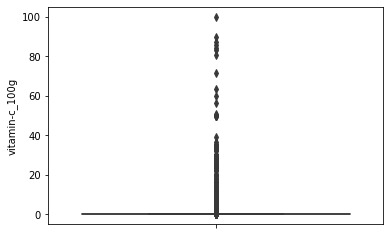

In [49]:
sns.boxplot(y='vitamin-c_100g',palette=["m", "g"],
            data=df5)

# Back to duplicate handling:

In [20]:
df5['product_brand'].value_counts().head(20)

Filet de poulet, La Nouvelle Agriculture           210
Filets de poulet, La Nouvelle Agriculture          127
Filets de poulet rôti, Le Gaulois                  106
Aiguillettes de poulet, La Nouvelle Agriculture    105
Les milanaises, Le Gaulois                          88
Jamón serrano, Bonarea                              82
Cuisses de poulet rôti, Le Gaulois                  82
Emmental, Eco+                                      77
Cuisses de poulet, La Nouvelle Agriculture          65
Jamón cocido al horno, Bonarea                      63
Filets de poulet roti, Le Gaulois                   63
Coca-Cola, Coca-Cola                                58
Comté, Le Berger Comtois                            54
Burger vegetariana, Bonarea                         54
Jamón serrano familiar, Bonarea                     53
Jambon à l'ancienne, Tallec                         52
Fuet extra con pavo, Bonarea                        52
Comté, JuraFlore                                    51
Fuet extra

In [21]:
df5[df5['product_brand']=='Comté, Le Berger Comtois'].describe()

,Ancien_Index,nutriscore_score,ecoscore_score_fr,nutrition-score-fr_100g,energy-kcal_100g,energy_100g,fat_100g,carbohydrates_100g,sugars_100g,proteins_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,potassium_100g,calcium_100g,polyunsaturated-fat_100g,vitamin-e_100g,vitamin-b1_100g,vitamin-b2_100g,vitamin-b6_100g,vitamin-b12_100g,magnesium_100g
count,54.000000,54.000000,54.000000,54.000000,54.000000,54.000000,54.0,54.0,54.000000,54.0,54.000000,54.0,54.0,54.0,54.0,54.0,54.0,54.0,54.0,54.0,54.0,54.0
mean,543790.722222,13.481481,34.259259,13.481481,422.037037,1798.703704,35.0,1.0,0.981481,27.0,0.488889,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
std,12142.454465,1.690604,1.389790,1.690604,58.515588,2.177324,0.0,0.0,0.136083,0.0,0.666012,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
min,542062.000000,13.000000,34.000000,13.000000,0.000000,1783.000000,35.0,1.0,0.000000,27.0,0.320000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,542091.750000,13.000000,34.000000,13.000000,430.000000,1799.000000,35.0,1.0,1.000000,27.0,0.320000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
50%,542134.500000,13.000000,34.000000,13.000000,430.000000,1799.000000,35.0,1.0,1.000000,27.0,0.320000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
75%,542192.500000,13.000000,34.000000,13.000000,430.000000,1799.000000,35.0,1.0,1.000000,27.0,0.320000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,631366.000000,20.000000,43.000000,20.000000,430.000000,1799.000000,35.0,1.0,1.000000,27.0,3.200000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [74]:
df5.columns

Index(['Ancien_Index', 'code', 'url', 'product_name', 'product_brand', 'generic_name', 'quantity', 'brands', 'categories', 'manufacturing_places', 'labels', 'emb_codes', 'purchase_places', 'stores', 'countries', 'ingredients_text', 'allergens', 'traces_tags', 'serving_size', 'nutriscore_score', 'nutriscore_grade', 'pnns_groups_1', 'pnns_groups_2', 'states', 'brand_owner', 'ecoscore_score_fr', 'ecoscore_grade_fr', 'main_category', 'image_url', 'image_ingredients_url', 'image_nutrition_url', 'nutrition-score-fr_100g', 'energy-kcal_100g', 'energy_100g', 'fat_100g', 'saturated-fat_100g', 'carbohydrates_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'sodium_100g', 'vitamin-a_100g', 'vitamin-c_100g', 'potassium_100g', 'calcium_100g', 'polyunsaturated-fat_100g', 'vitamin-e_100g', 'vitamin-b1_100g', 'vitamin-b2_100g', 'vitamin-b6_100g', 'vitamin-b12_100g', 'magnesium_100g'], dtype='object')

In [9]:
d2 = {'Ancien_Index':'first',
      'code':'first',
    'url':'first',
 'product_name':'first',
 'generic_name':'first',
 'quantity':'first',
 'brands':'first',
 'categories':'first',
 'manufacturing_places':'first',
 'labels':'first',
 'emb_codes':'first',
 'purchase_places':'first',
 'stores':'first',
 'countries':'first',
 'ingredients_text':'first',
 'allergens':'first',
 'traces_tags':'first',
 'serving_size':'first',
 'nutriscore_score':'median',
 'nutriscore_grade':'first',
'pnns_groups_1':'first',
'pnns_groups_2':'first',
'states':'first',
 'brand_owner':'first',
 'ecoscore_score_fr':'median',
 'ecoscore_grade_fr':'first',
 'main_category':'first',
 'image_url':'first',
 'image_ingredients_url':'first',
 'image_nutrition_url':'first',
 'energy-kcal_100g':'median',
 'energy_100g':'median',
 'fat_100g':'median',
      'saturated-fat_100g':'median',
 'carbohydrates_100g':'median',
 'sugars_100g':'median',
 'fiber_100g':'median',
      'proteins_100g':'median',
 'sodium_100g':'median',
 'vitamin-a_100g':'median',
 'vitamin-c_100g':'median',
 'potassium_100g':'median',
 'calcium_100g':'median',
 'nutrition-score-fr_100g':'median',
 'polyunsaturated-fat_100g':'median',
 'vitamin-e_100g':'median',
 'vitamin-b1_100g':'median',
 'vitamin-b2_100g':'median',
 'vitamin-b6_100g':'median',
 'vitamin-b12_100g':'median',
 'magnesium_100g':'median'}

df6 = (df5.groupby(['product_brand'], sort=False, as_index=False).agg(d2).reindex(columns=df5.columns))

# possible bug caused by unique base records (in d5) with NaN in their features


# build a table with the unique values, the number of duplicates and the max for each unique value.
# remove from df5 the rows whose value equals the max if the max is >= 10*median.

df5_doublons=df5['product_brand'].value_counts().rename_axis('unique_values').to_frame('counts')
df5_doublons['index']=df5_doublons.index

# create a column with Q3 for each product_brand
# df.describe() returns a summary of a dataframe, e.g.:

#df5['vitamin-b12_100g'].describe()['max']  --> gives the max of column df5['vitamin-b12_100g']

#df5[df5['product_brand']=='Filet de poulet, La Nouvelle Agriculture']['vitamin-b12_100g'].describe()['max'] --> gives the describe() max of the rows containing 'Filet de po...'
# in product_brand, for column 'vitamin-b12_100g'

# we want the max for each value in a new column.

# for each element of df5_doublons, show the max:
Liste_Int=['nutriscore_score',
'ecoscore_score_fr',
'energy-kcal_100g',
 'energy_100g',
 'fat_100g',
 'carbohydrates_100g',
 'sugars_100g',
 'proteins_100g',
 'sodium_100g',
 'vitamin-a_100g',
 'vitamin-c_100g',
 'potassium_100g',
 'calcium_100g',
 'nutrition-score-fr_100g',
 'polyunsaturated-fat_100g',
 'vitamin-e_100g',
 'vitamin-b1_100g',
 'vitamin-b2_100g',
 'vitamin-b6_100g',
 'vitamin-b12_100g',
 'magnesium_100g']

for i in Liste_Int:
    for j in Liste_index_doublonsdf5:
        df5[i+'_max']=df5[df5['product_brand']==j][i].describe()['max']
    
#--> too slow (again). We take a sample of product_brand values and check whether using the median makes sense.

--> for a future study, a function could compute the max of each group.
That max would then be assigned to the new column.


In [115]:
#len(Liste_index_doublonsdf5)
df6.shape

(561563, 52)

In [10]:
from numpy.random import default_rng

rng = default_rng()
numbers = rng.choice(566559, size=10, replace=False)

numbers

array([196845, 209238, 384714, 466966, 558022, 158547, 185460, 121975,
       415028,  91691], dtype=int64)

Rappel :
    Liste_Int=['nutriscore_score',
'ecoscore_score_fr',
'energy-kcal_100g',
 'energy_100g',
 'fat_100g',
 'carbohydrates_100g',
 'sugars_100g',
 'proteins_100g',
 'sodium_100g',
 'vitamin-a_100g',
 'vitamin-c_100g',
 'potassium_100g',
 'calcium_100g',
 'nutrition-score-fr_100g',
 'polyunsaturated-fat_100g',
 'vitamin-e_100g',
 'vitamin-b1_100g',
 'vitamin-b2_100g',
 'vitamin-b6_100g',
 'vitamin-b12_100g',
 'magnesium_100g']



In [72]:
#df5[df5['product_brand']==Liste_index_doublonsdf5[numbers[0]]]['nutriscore_score'].describe()

In [73]:
#df5[df5['product_brand']==Liste_index_doublonsdf5[numbers[1]]]['ecoscore_score_fr'].describe()

In [74]:
#df5[df5['product_brand']==Liste_index_doublonsdf5[numbers[2]]]['vitamin-a_100g'].describe()

In [75]:
#df5[df5['product_brand']==Liste_index_doublonsdf5[numbers[9]]]['vitamin-c_100g'].describe()

In [77]:
#del df6['nutriscore_score_max']

# df6['main_category'] = df6['main_category'].replace({np.nan:'missing value'})

#df3["main_category"] = df3.main_category.astype(str)

In [116]:
#df3["main_category"] = df3.main_category.astype(str)

df6.isna().sum()


Ancien_Index                     0
code                             0
url                              0
product_name                     0
product_brand                    0
generic_name                465220
quantity                    281934
brands                           0
categories                   60967
manufacturing_places        468882
labels                      349160
emb_codes                   484586
purchase_places             437845
stores                      393153
countries                      902
ingredients_text            112402
allergens                   444413
traces_tags                 457782
serving_size                277184
nutriscore_score            112665
nutriscore_grade            112665
pnns_groups_1                   45
pnns_groups_2                    0
states                           0
brand_owner                 421121
ecoscore_score_fr           293371
ecoscore_grade_fr           293371
main_category                60967
image_url           

In [11]:
df6.rename(columns={'vitamin-a_100g':'vitamin_a_100g'},inplace=True)
df6.rename(columns={'vitamin-c_100g':'vitamin_c_100g'},inplace=True)
df6.rename(columns={'nutrition-score-fr_100g':'nutrition_score_fr_100g'},inplace=True)
df6.rename(columns={'polyunsaturated-fat_100g':'polyunsaturated_fat_100g'},inplace=True)
df6.rename(columns={'vitamin-e_100g':'vitamin_e_100g'},inplace=True)
df6.rename(columns={'vitamin-b1_100g':'vitamin_b1_100g'},inplace=True)
df6.rename(columns={'vitamin-b2_100g':'vitamin_b2_100g'},inplace=True)
df6.rename(columns={'vitamin-b6_100g':'vitamin_b6_100g'},inplace=True)
df6.rename(columns={'vitamin-b12_100g':'vitamin_b12_100g'},inplace=True)
df6.rename(columns={'saturated-fat_100g':'saturated_fat_100g'},inplace=True)


list(df6.columns)
# Initial model (error: 22%):

#list_x=['vitamin_a_100g',
# 'vitamin_c_100g',
# 'potassium_100g',
# 'calcium_100g',
# 'nutrition_score_fr_100g',
# 'polyunsaturated_fat_100g',
# 'vitamin_e_100g',
# 'vitamin_b1_100g',
# 'vitamin_b2_100g',
# 'vitamin_b6_100g',
# 'vitamin_b12_100g',
# 'magnesium_100g']




df6.columns
df6.shape[0]

561563

In [135]:
df6.isna().sum()
df6['countries'].value_counts()

France                                  200261
United States                           153828
España                                   26218
Deutschland                              15053
en:Germany                                8555
                                         ...  
Denmark, Netherlands                         1
Brasil, Paraguai, Uruguai, Venezuela         1
Italy,United States                          1
European Union,France                        1
Francia,España,Italia                        1
Name: countries, Length: 7810, dtype: int64

df6['vitamin_a_100g'] = df6.vitamin_a_100g.round().astype('Int64')
df6['vitamin_c_100g'] = df6.vitamin_c_100g.round().astype('Int64')
df6['potassium_100g'] = df6.potassium_100g.round().astype('Int64')
df6['calcium_100g'] = df6.calcium_100g.round().astype('Int64')
df6['nutrition_score_fr_100g'] = df6.nutrition_score_fr_100g.round().astype('Int64')
df6['polyunsaturated_fat_100g'] = df6.polyunsaturated_fat_100g.round().astype('Int64')
df6['vitamin_e_100g'] = df6.vitamin_e_100g.round().astype('Int64')
df6['vitamin_b1_100g'] = df6.vitamin_b1_100g.round().astype('Int64')
df6['vitamin_b2_100g'] = df6.vitamin_b2_100g.round().astype('Int64')
df6['vitamin_b6_100g'] = df6.vitamin_b6_100g.round().astype('Int64')
df6['vitamin_b12_100g'] = df6.vitamin_b12_100g.round().astype('Int64')
df6['magnesium_100g'] = df6.magnesium_100g.round().astype('Int64')
df6['polyunsaturated_fat_100g'] = df6.polyunsaturated_fat_100g.round().astype('Int64')
df6['nutriscore_score'] = df6.nutriscore_score.round().astype('Int64')

# End of cleaning. Start of the exploratory analysis. 


In [19]:
df7=df6[['Ancien_Index', 'code','product_name','image_nutrition_url', 'brands','product_brand','categories','countries','nutriscore_score', 'nutriscore_grade', 'pnns_groups_1', 'pnns_groups_2',
         'energy-kcal_100g', 'energy_100g','fat_100g', 'saturated_fat_100g', 'carbohydrates_100g', 'sugars_100g', 'proteins_100g', 'sodium_100g', 'fiber_100g', 
         'vitamin_a_100g', 'vitamin_c_100g','potassium_100g', 'calcium_100g', 'polyunsaturated_fat_100g', 'vitamin_e_100g',
         'vitamin_b1_100g', 'vitamin_b2_100g', 'vitamin_b6_100g', 'vitamin_b12_100g', 
         'magnesium_100g']]

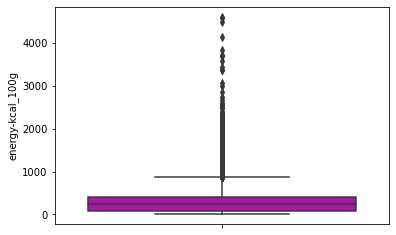

875.0


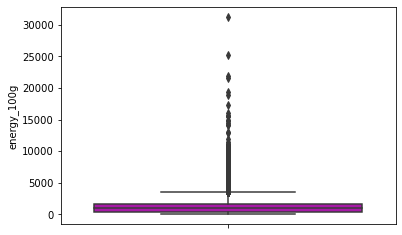

3559.0


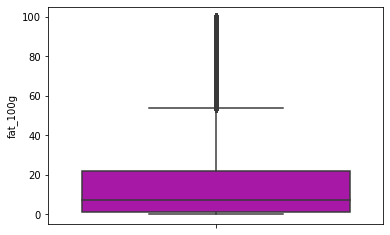

53.8


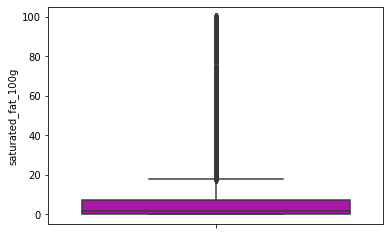

18.1


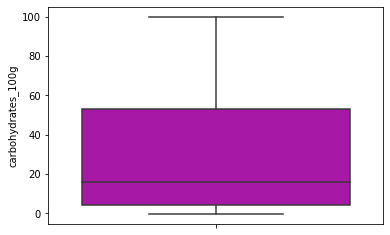

126.15


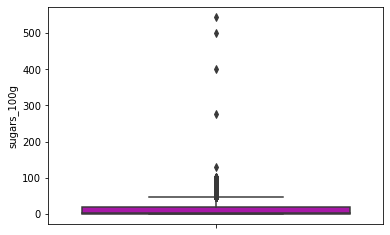

46.150000000000006


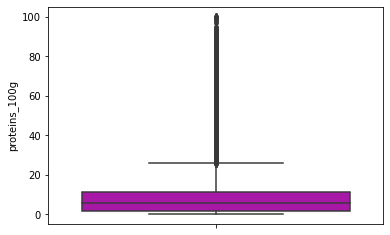

26.200000000000003


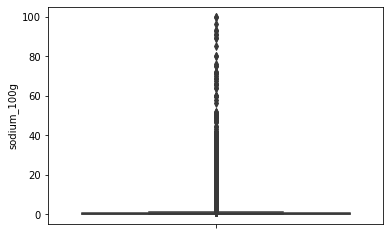

1.252


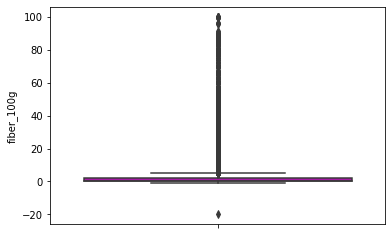

5.25


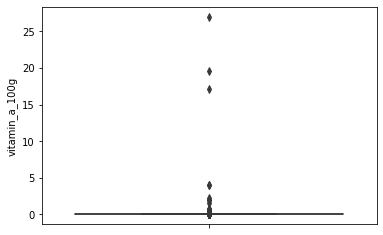

0.0


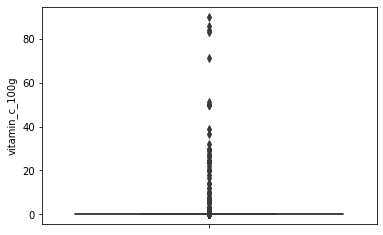

0.0


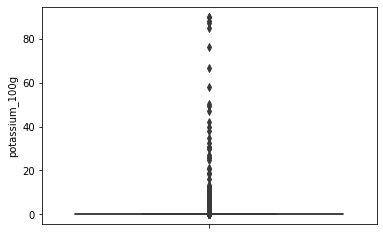

0.0


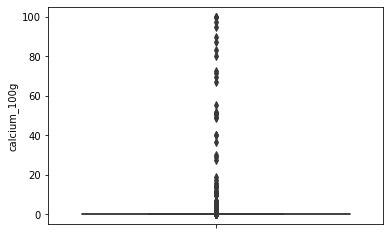

0.0


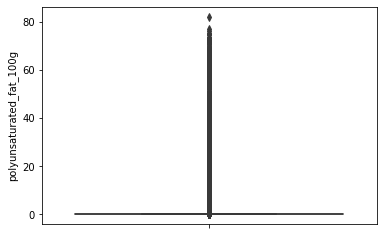

0.0


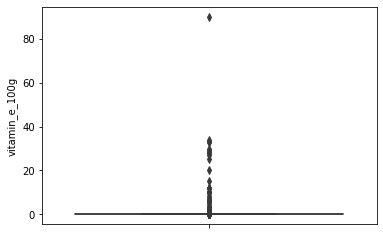

0.0


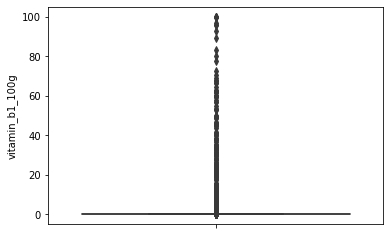

0.0


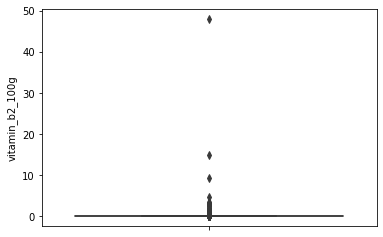

0.0


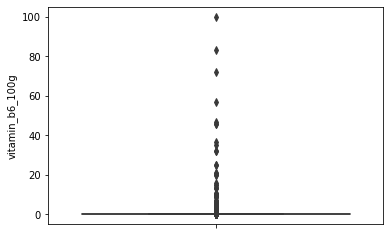

0.0


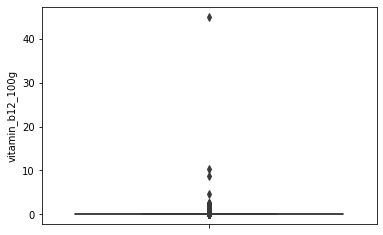

0.0


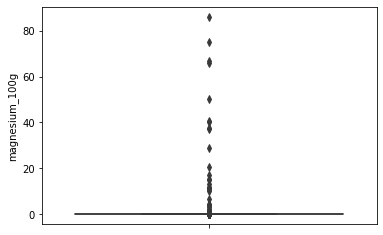

0.0


In [20]:
liste_nutri=['energy-kcal_100g', 'energy_100g','fat_100g', 'saturated_fat_100g', 'carbohydrates_100g', 'sugars_100g', 'proteins_100g', 'sodium_100g', 'fiber_100g', 
         'vitamin_a_100g', 'vitamin_c_100g','potassium_100g', 'calcium_100g', 'polyunsaturated_fat_100g', 'vitamin_e_100g',
         'vitamin_b1_100g', 'vitamin_b2_100g', 'vitamin_b6_100g', 'vitamin_b12_100g', 
         'magnesium_100g']

for i in liste_nutri:
    sns.boxplot(y=i,palette=["m", "g"],
            data=df7)
    plt.show()
    print(df7[i].describe()[6]+1.5*(df7[i].describe()[6]-df7[i].describe()[4]))

In [21]:
df7=df7[df7['sodium_100g']<50]
df7=df7[df7['sugars_100g']<100]
df7=df7[df7['fiber_100g']>=0]

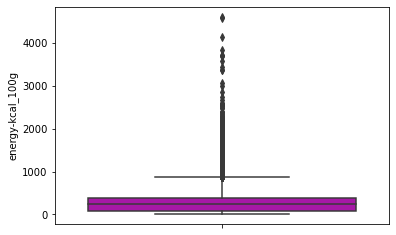

872.5


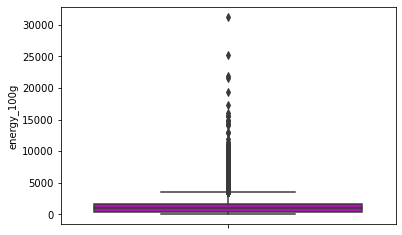

3559.0


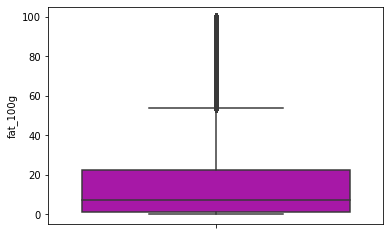

53.989999999999995


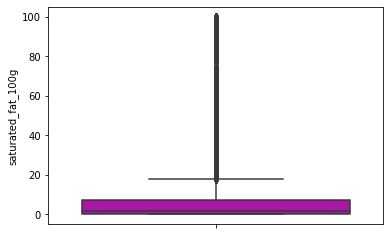

18.1


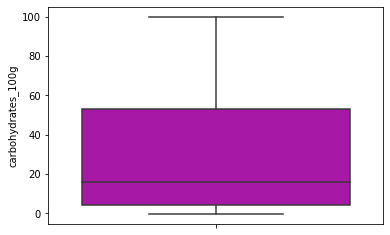

125.9


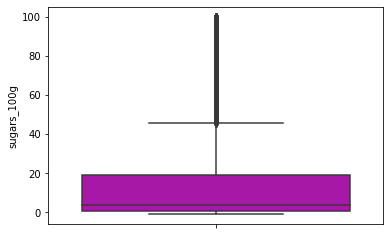

45.9


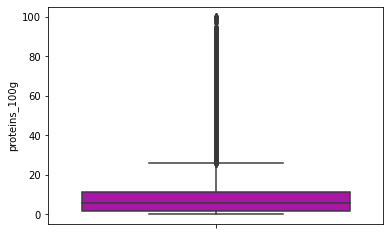

26.224999999999998


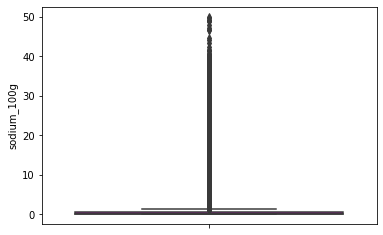

1.252


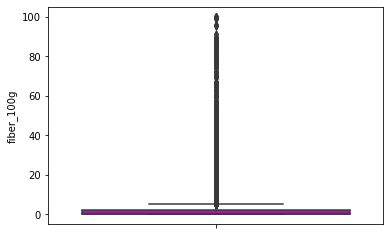

5.25


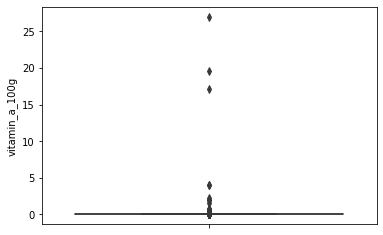

0.0


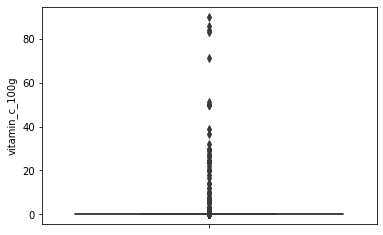

0.0


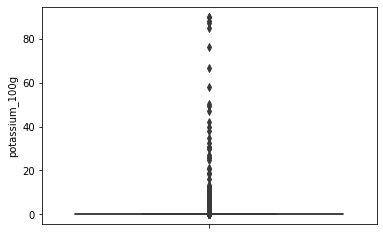

0.0


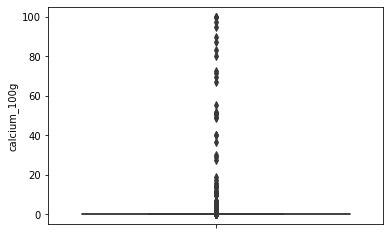

0.0


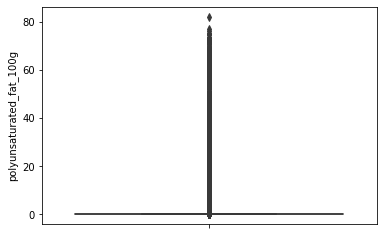

0.0


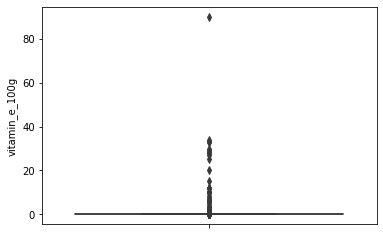

0.0


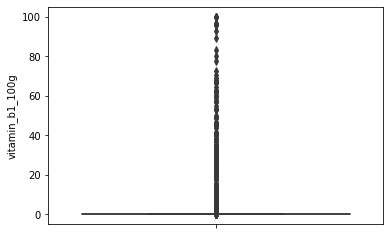

0.0


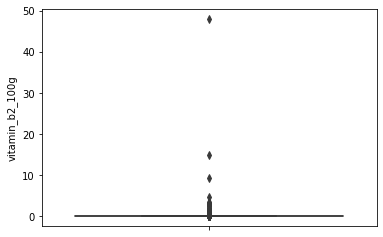

0.0


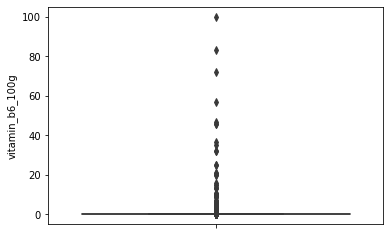

0.0


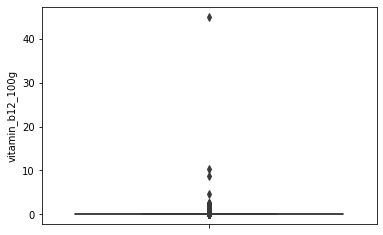

0.0


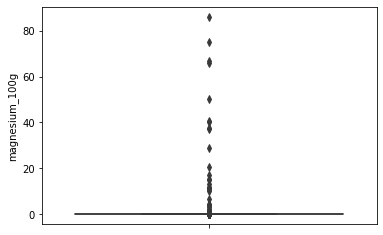

0.0


In [22]:
for i in liste_nutri:
    sns.boxplot(y=i,palette=["m", "g"],
            data=df7)
    plt.show()
    print(df7[i].describe()[6]+1.5*(df7[i].describe()[6]-df7[i].describe()[4]))

# Bivariate analysis:

## Correlation matrix

<AxesSubplot:>

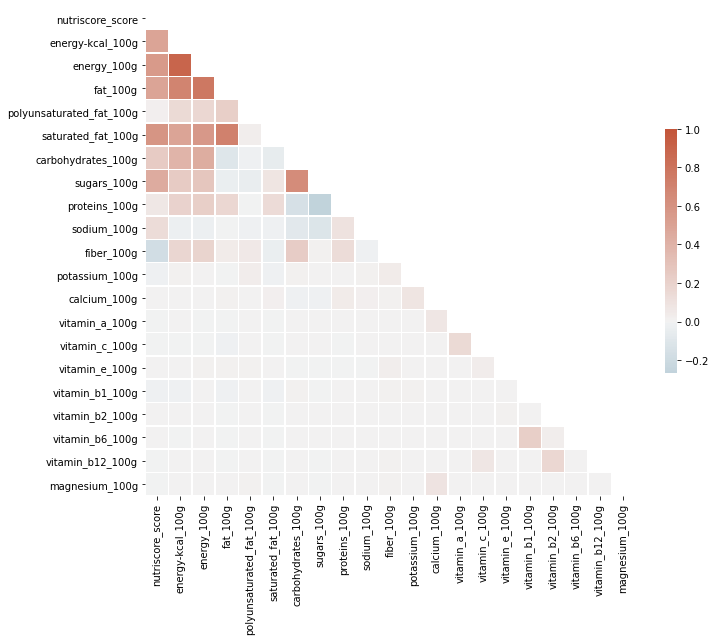

In [24]:
df10=df7[['code', 'product_name', 'image_nutrition_url', 'brands', 'product_brand', 'categories', 'countries', 'nutriscore_score',
          'nutriscore_grade', 'pnns_groups_1', 'pnns_groups_2', 'energy-kcal_100g', 'energy_100g', 'fat_100g', 'polyunsaturated_fat_100g' ,'saturated_fat_100g', 
          'carbohydrates_100g', 'sugars_100g', 'proteins_100g', 'sodium_100g', 'fiber_100g',
          'potassium_100g', 'calcium_100g','vitamin_a_100g', 'vitamin_c_100g', 'vitamin_e_100g',
         'vitamin_b1_100g', 'vitamin_b2_100g', 'vitamin_b6_100g', 'vitamin_b12_100g', 
         'magnesium_100g']]


corr_df10 = df10.corr()

corr_df10


# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr_df10, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr_df10, mask=mask, cmap=cmap, vmax=1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

In [30]:
# what we keep for the Nutri-Score:

list_20=['energy_100g',
'fat_100g','saturated_fat_100g', 'carbohydrates_100g',
'sugars_100g', 'sodium_100g', 'fiber_100g'] 

In [ ]:
# Boxplots en fonction de nutriscore grade



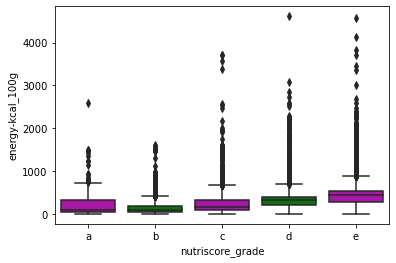

872.5


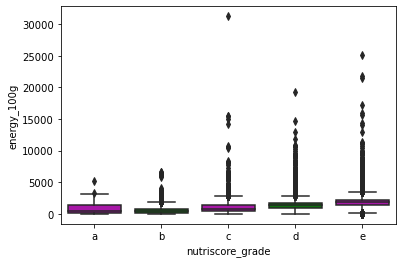

3559.0


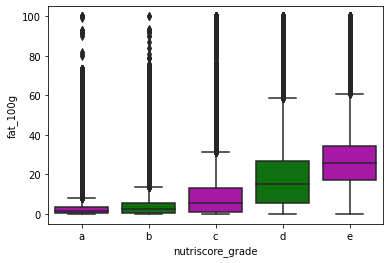

53.989999999999995


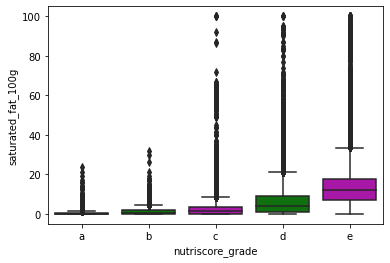

18.1


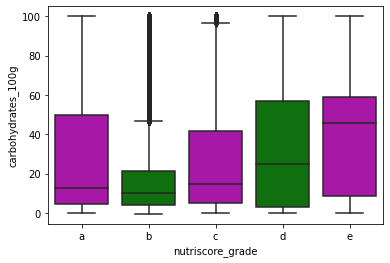

125.9


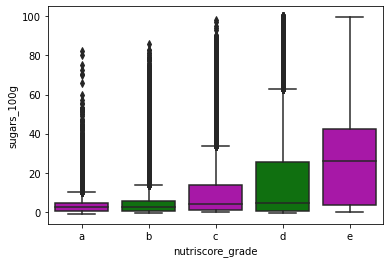

45.9


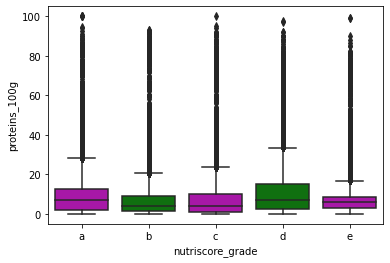

26.224999999999998


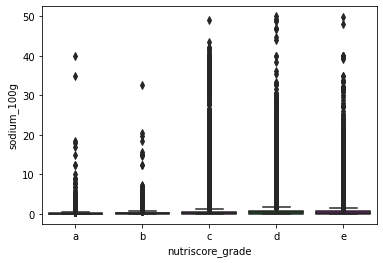

1.252


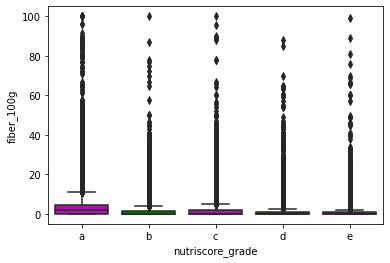

5.25


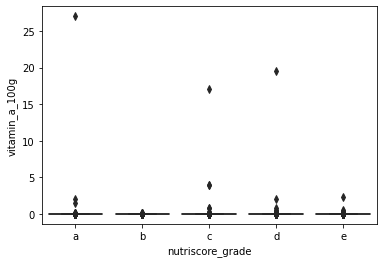

0.0


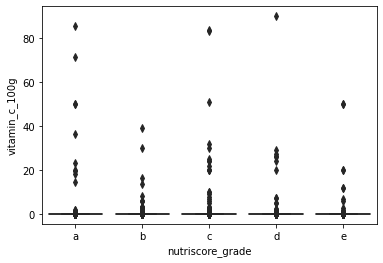

0.0


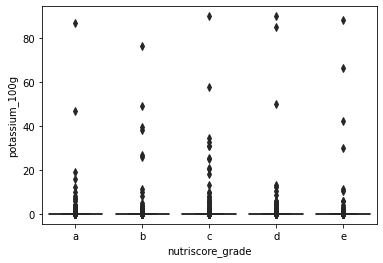

0.0


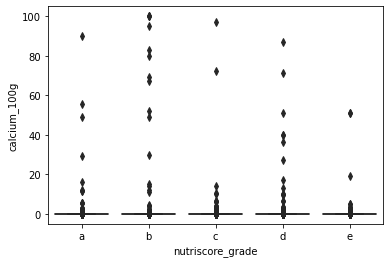

0.0


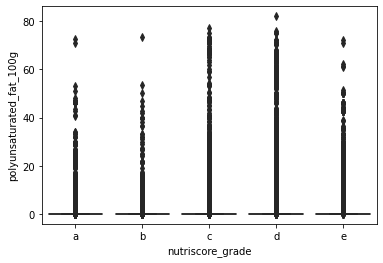

0.0


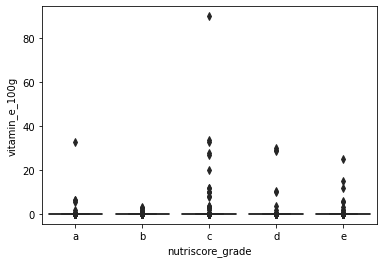

0.0


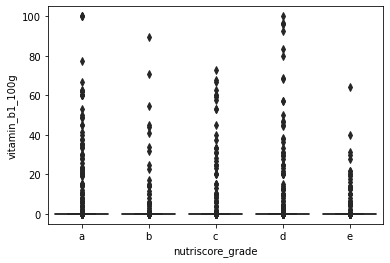

0.0


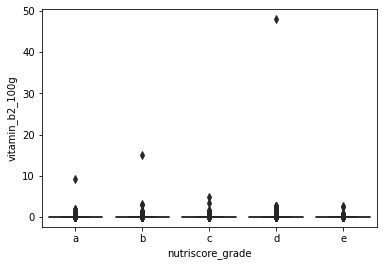

0.0


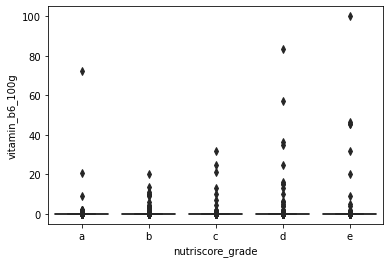

0.0


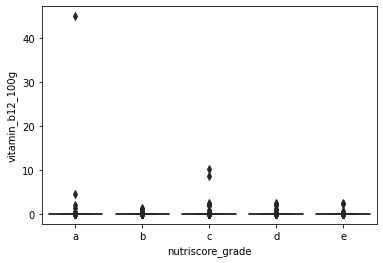

0.0


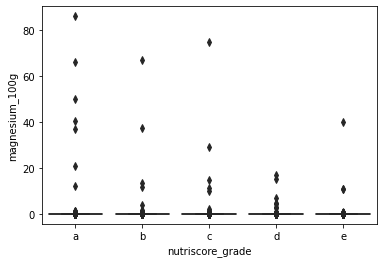

0.0


In [37]:
#liste_nutri2=['energy-kcal_100g', 'energy_100g','fat_100g', 'saturated_fat_100g', 'carbohydrates_100g', 'sugars_100g', 'proteins_100g', 'sodium_100g', 'fiber_100g']

liste_alpha=['a','b','c','d','e']

list_nutri=['energy-kcal_100g', 'energy_100g','fat_100g', 'saturated_fat_100g', 'carbohydrates_100g', 'sugars_100g', 'proteins_100g', 'sodium_100g', 'fiber_100g', 
         'vitamin_a_100g', 'vitamin_c_100g','potassium_100g', 'calcium_100g', 'polyunsaturated_fat_100g', 'vitamin_e_100g',
         'vitamin_b1_100g', 'vitamin_b2_100g', 'vitamin_b6_100g', 'vitamin_b12_100g', 
         'magnesium_100g']

for i in list_nutri:
    sns.boxplot(x='nutriscore_grade',y=i,palette=["m", "g"],order=liste_alpha,
            data=df7)

    plt.show()
    print(df7[i].describe()[6]+1.5*(df7[i].describe()[6]-df7[i].describe()[4]))
    
    


## ACP (ANALYSE EN COMPOSANTES PRINCIPALES) 

#### Utiliser moins de vecteurs (illisible)


In [32]:
from sklearn import decomposition
from sklearn import preprocessing

from functions_Copy8 import *

os.path.abspath("functions.py")

'.\\functions.py'

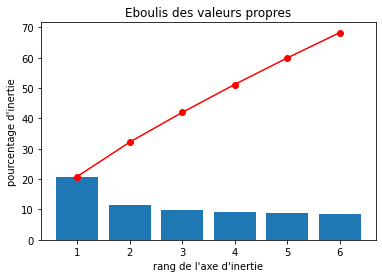

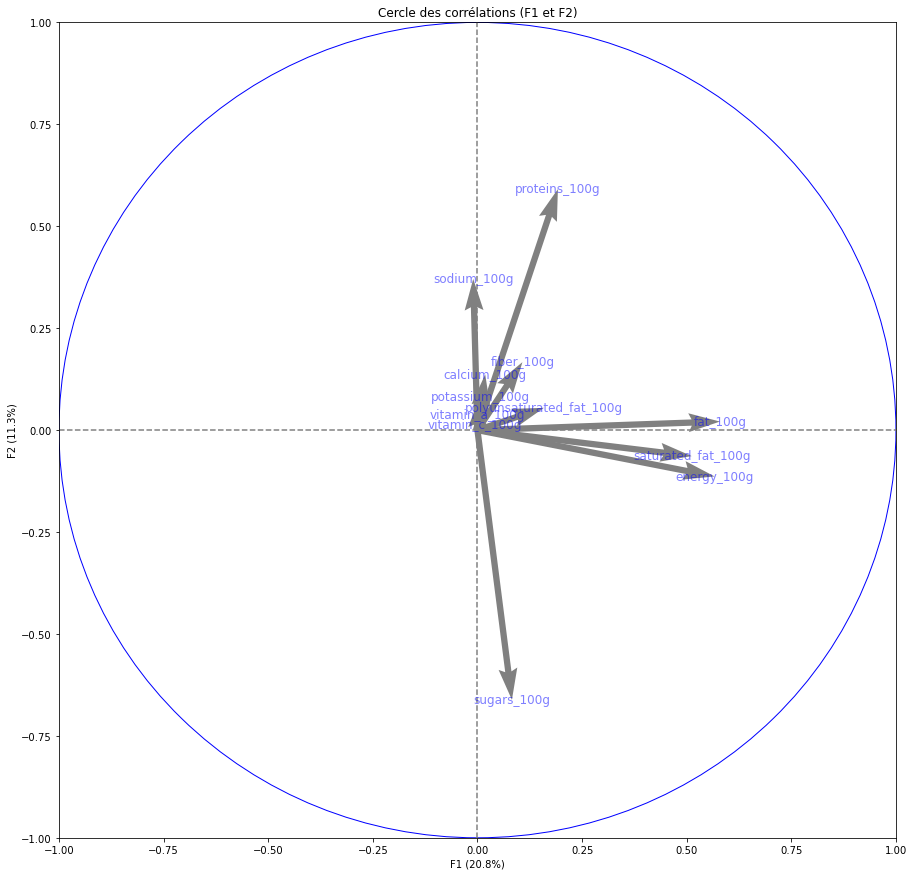

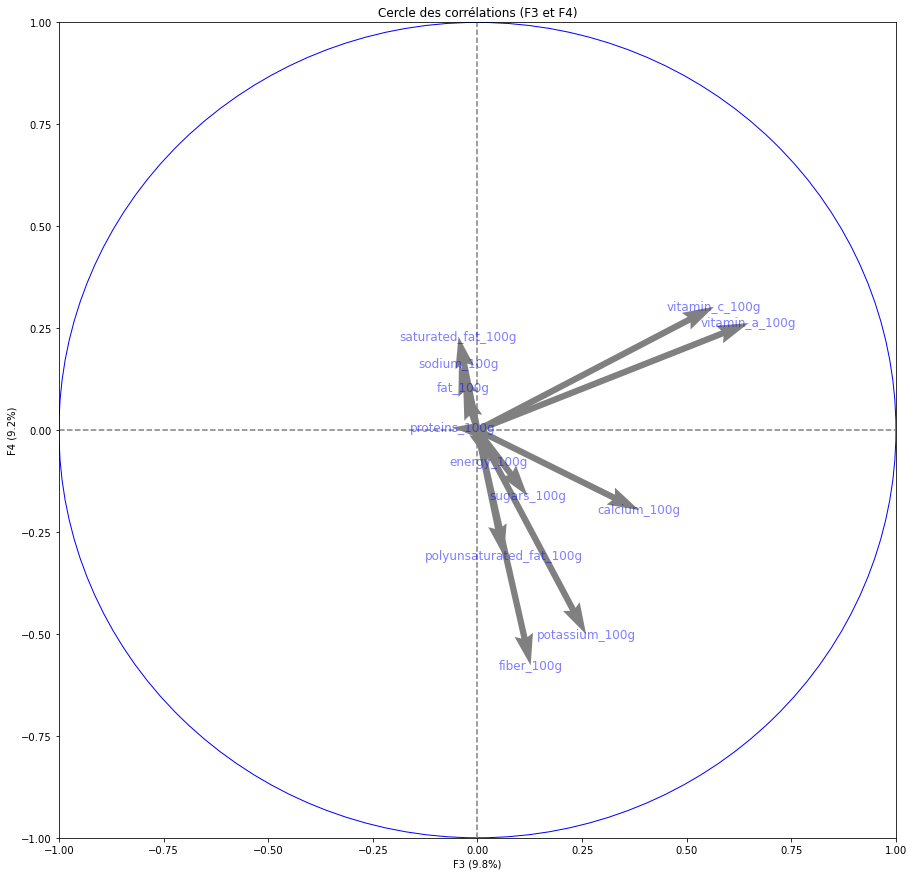

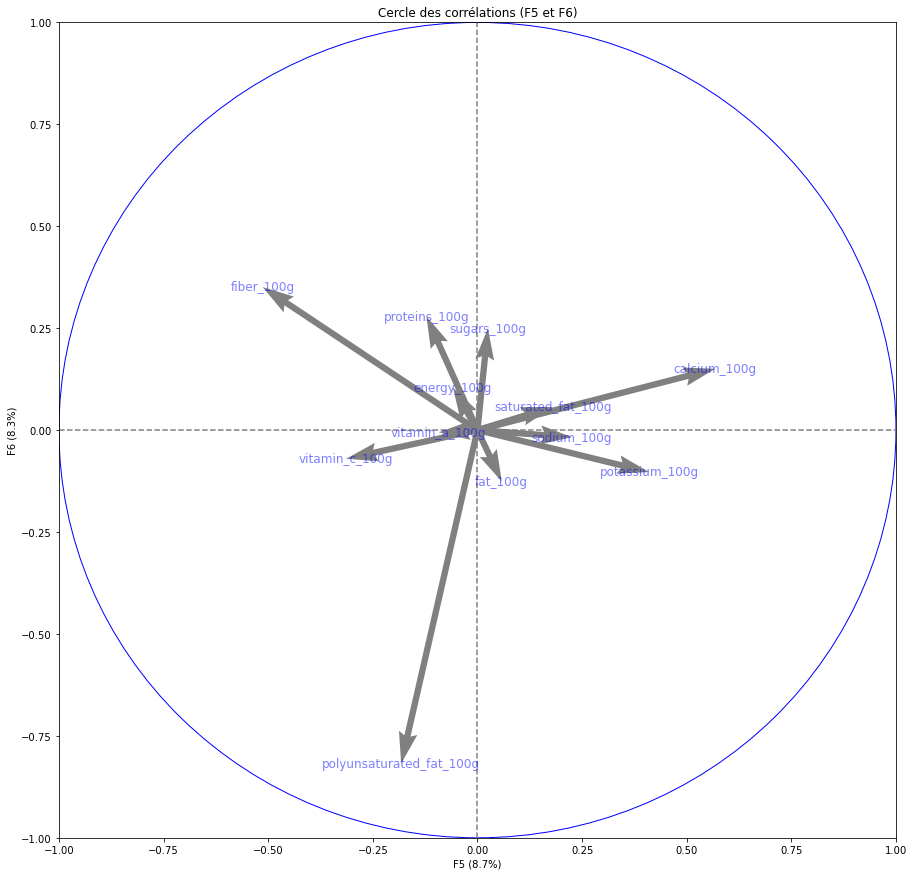

In [33]:
# choose the number of components to compute
n_comp = 6

list_20=['predicted_nutrition_score',
'energy_100g',
'fat_100g', 'polyunsaturated_fat_100g' ,'saturated_fat_100g', 
'sugars_100g', 'proteins_100g', 'sodium_100g', 'fiber_100g', 
          'potassium_100g', 'calcium_100g','vitamin_a_100g', 'vitamin_c_100g'] 

list_21=['energy_100g',
'fat_100g', 'polyunsaturated_fat_100g' ,'saturated_fat_100g', 
'sugars_100g', 'proteins_100g', 'sodium_100g', 'fiber_100g', 
          'potassium_100g', 'calcium_100g','vitamin_a_100g', 'vitamin_c_100g'] 

# select the columns used in the PCA
data_pca = df7[list_21]

# Nutri_score grade :
nutri = [df7.loc[Id, 'nutriscore_grade'] for Id in data_pca.index]

# prepare the data for the PCA
#data_pca = data_pca.fillna(data_pca.mean()) # unknown values are often replaced by the variable's mean
X = data_pca.values
names = df7["product_name"] # or data.index to get the labels
features = data_pca.columns

# Centring and scaling
std_scale = preprocessing.StandardScaler().fit(X)
X_scaled = std_scale.transform(X)

# Compute the principal components
pca = decomposition.PCA(n_components=n_comp)
pca.fit(X_scaled)

# Scree plot
display_scree_plot(pca)

# Correlation circle
pcs = pca.components_
display_circles(pcs, n_comp, pca, [(0,1),(2,3),(4,5)], labels = np.array(features))


plt.show()


# --------------------------------




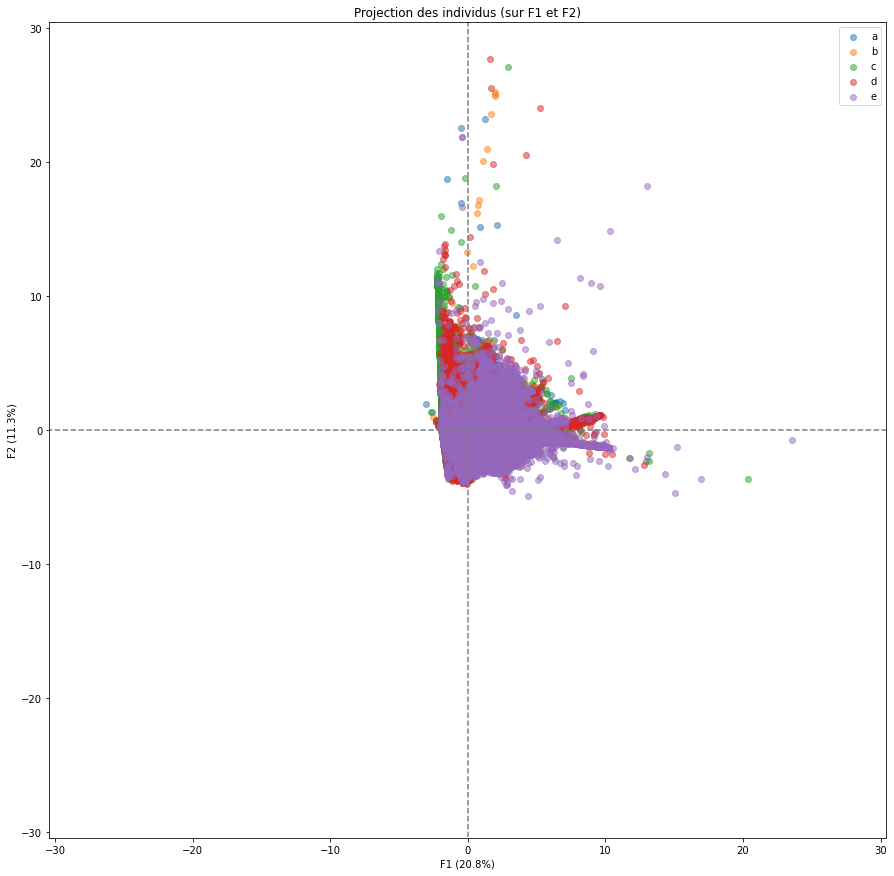

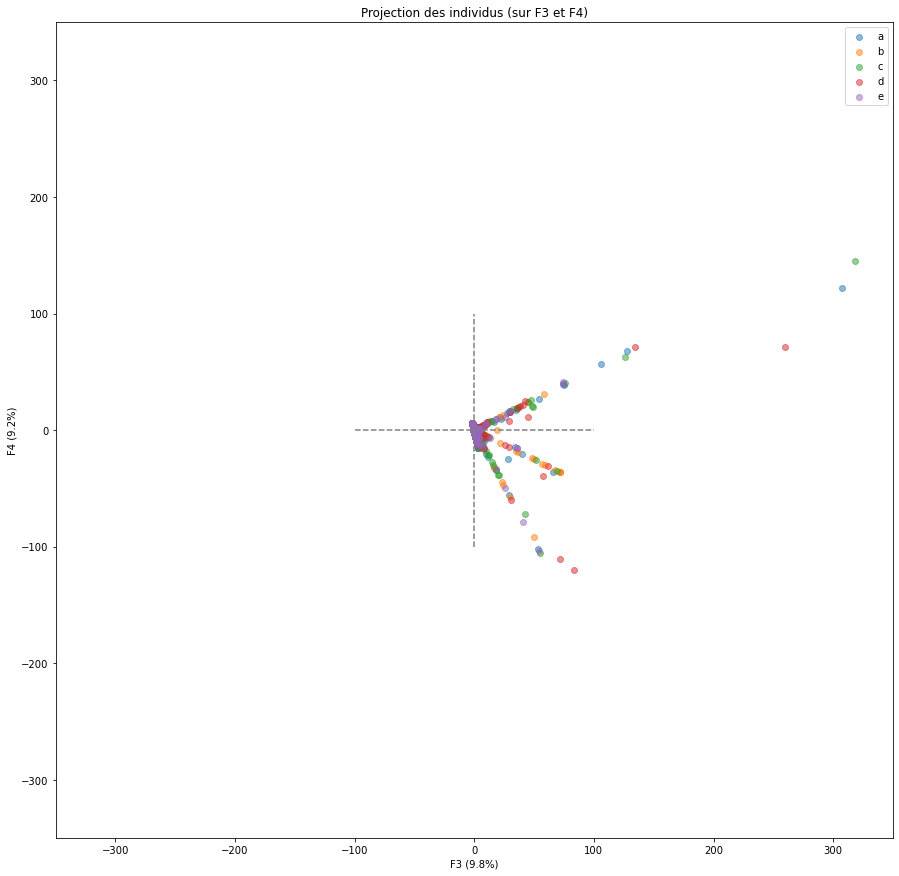

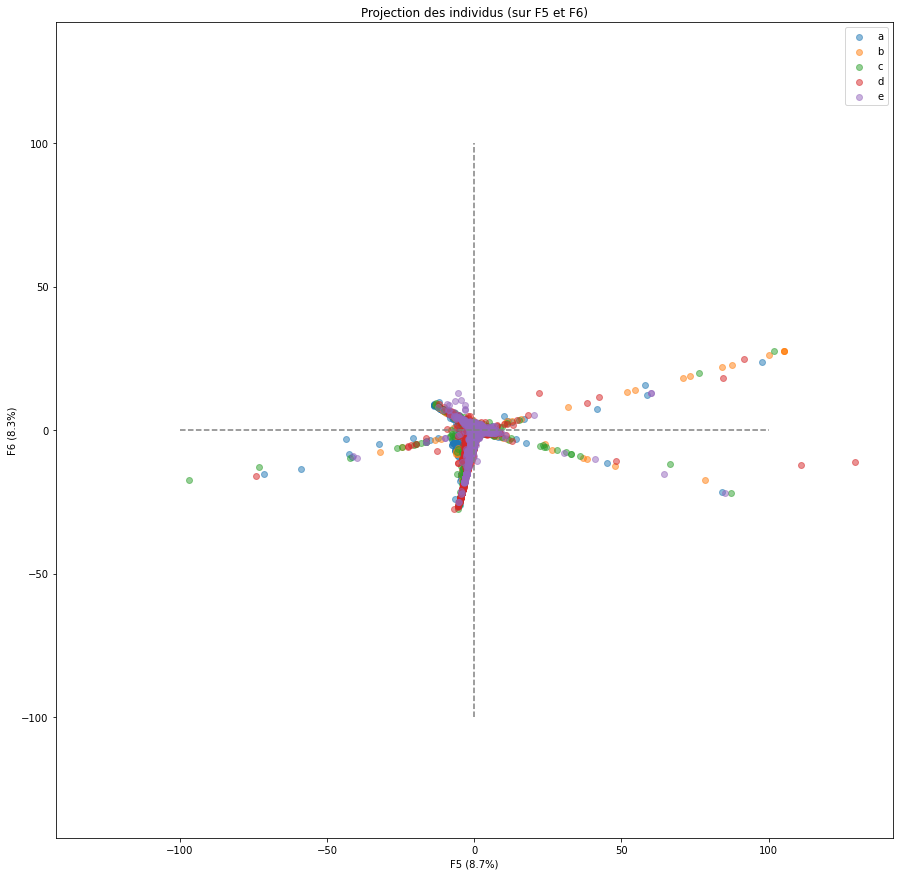

In [34]:
# Projection of the individuals
X_projected = pca.transform(X_scaled)
display_factorial_planes(X_projected, n_comp, pca, [(0,1),(2,3),(4,5)], illustrative_var = nutri, alpha = 0.5)

# Computing the nutrition score 

## Linear regression to estimate the Nutri-Score

In [113]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

df7_noNa=df7[~df7["nutriscore_score"].isna()]

In [120]:
mod = sm.regression.linear_model.OLS.from_formula(formula='nutriscore_score ~ energy_100g + fat_100g+saturated_fat_100g+carbohydrates_100g+sugars_100g+sodium_100g+fiber_100g',
                                     data=df7_noNa)

res=mod.fit()


#xdat = rets['EUROSTOXX']
#xdat = sm.add_constant(xdat)
#ydat = rets['VSTOXX']
#model = sm.OLS(y=ydat,x=xdat).fit()


print(res.summary())

                            OLS Regression Results                            
Dep. Variable:       nutriscore_score   R-squared:                       0.604
Model:                            OLS   Adj. R-squared:                  0.604
Method:                 Least Squares   F-statistic:                 9.761e+04
Date:                Tue, 27 Jul 2021   Prob (F-statistic):               0.00
Time:                        15:38:33   Log-Likelihood:            -1.4107e+06
No. Observations:              448898   AIC:                         2.821e+06
Df Residuals:                  448890   BIC:                         2.821e+06
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              1.3414      0

## KNN 

In [91]:
df7=df6[['Ancien_Index', 'code','product_name','image_nutrition_url', 'brands','product_brand','categories','countries','nutriscore_score', 'nutriscore_grade', 'pnns_groups_1', 'pnns_groups_2',
         'energy-kcal_100g', 'energy_100g','fat_100g', 'saturated_fat_100g', 'carbohydrates_100g', 'sugars_100g', 'proteins_100g', 'sodium_100g', 'fiber_100g', 
         'vitamin_a_100g', 'vitamin_c_100g','potassium_100g', 'calcium_100g', 'polyunsaturated_fat_100g', 'vitamin_e_100g',
         'vitamin_b1_100g', 'vitamin_b2_100g', 'vitamin_b6_100g', 'vitamin_b12_100g', 
         'magnesium_100g']]


# Train the model on rows where nutriscore_score is not NaN
df7_noNa=df7[~df7["nutriscore_score"].isna()]


# 0.49 : list_x=['energy-kcal_100g','sugars_100g','saturated_fat_100g','sodium_100g','proteins_100g']

# 'energy_100g','sodium_100g','proteins_100g','carbohydrates_100g','fat_100g'

# 0.45: sample fraction 1, train 0.9/test: list_x=['energy_100g','sugars_100g','saturated_fat_100g','sodium_100g','proteins_100g']

# what we keep for the Nutri-Score:

list_20=['energy_100g',
'fat_100g','saturated_fat_100g', 'carbohydrates_100g',
'sugars_100g', 'sodium_100g', 'fiber_100g'] 


list_x=list_20

from sklearn import preprocessing
lab_enc = preprocessing.LabelEncoder()
str_enc=preprocessing.OneHotEncoder(handle_unknown='ignore')

from numpy.random import default_rng


rng = default_rng()
sample=rng.choice(df7_noNa.shape[0],size=int(1*df7_noNa.shape[0]))
sample_data=df7_noNa.iloc[sample]

#sample_dataV2=sample_data.dropna(subset = ['nutriscore_score'], inplace=False)

from sklearn.model_selection import train_test_split

X=sample_data[list_x]
#encoded_X=str_enc.fit_transform(X)
y=sample_data["nutriscore_score"]
encoded_y = lab_enc.fit_transform(y)

#len(X),len(encoded_y)

xtrain,xtest,ytrain,ytest=train_test_split(X,encoded_y,train_size=0.8)

from sklearn import neighbors
knn=neighbors.KNeighborsRegressor(n_neighbors=2)
knn.fit(xtrain,ytrain)    # --> issue: ytrain has NaN values. They are removed from the sample on the sample_dataV2 line

# Warning: nutriscore_score was converted to int only for the sample. Do it for the whole dataset.
# New issue: values are continuous and must be converted to integers. Seems complicated with NaN. Int64.
#Error : cannot safely cast non-equivalent float64 to int32
#Unknown label type: 'unknown'

score=knn.score(xtest,ytest)
score

# warning: df6 and df7 are modified

0.8906452463046122

score R2 : 0.89


<function matplotlib.pyplot.show(close=None, block=None)>

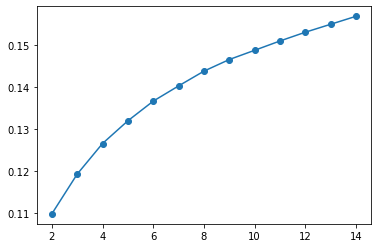

In [39]:
# slow to run:

errors=[]
for k in range(2,15):
    knn=neighbors.KNeighborsRegressor(k)
    errors.append(1-knn.fit(xtrain,ytrain).score(xtest,ytest))
plt.plot(range(2,15),errors,'o-')
plt.show

# we use k=2 for KNN by default

from sklearn import preprocessing
lab_enc = preprocessing.LabelEncoder()
str_enc=preprocessing.OneHotEncoder(handle_unknown='ignore')

from numpy.random import default_rng


rng = default_rng()
sample=rng.choice(566559,size=int(0.1*566559))
sample_data=df6.iloc[sample]

#sample_dataV2=sample_data.dropna(subset = ['nutriscore_score'], inplace=False)

from sklearn.model_selection import train_test_split

X=sample_data[list_x]
encoded_X=str_enc.fit_transform(X)
y=sample_data["nutriscore_score"]
encoded_y = lab_enc.fit_transform(y)

X.shape
encoded_X

In [92]:
# we used a sample of 100% of df6 for the model
# the model was trained on rows where the Nutri-Score was available (df7)
# it then has to be applied to df6 (where the Nutri-Score is not always available)
# on the sample, 90% is used for training and 10% for testing
# we get predictions for xtest from the KNN model (trained on xtrain, ytrain)
# More precisely, the KNN model is applied to xtest and the result compared with ytest, which gives the score.

knn = neighbors.KNeighborsClassifier(2)
knn.fit(xtrain, ytrain)

predictions = knn.predict(xtest)
predictions

array([29, 67, 29, ..., 47, 69, 81], dtype=int64)

In [93]:
# ambiguous values. Strange that ytest returns values like '3594' while the max of y is 40
# may be caused by lab_enc.fit_transform:
# remember to apply .inverse_transform!

lab_enc.inverse_transform(predictions)

array([ 1., 20.,  1., ..., 10., 21., 27.])

In [94]:
# all that is left is to apply the model to the whole df7 dataframe (where the Nutri-Score is not always available)

x_pred=(df7[list_x])

prediction = knn.predict(x_pred)


# --> the difficulty comes from the str_enc encoder. Either dig into it, or remove the product_name string from x_list





In [95]:
prediction
lab_enc.inverse_transform(prediction)

array([11., 14.,  1., ..., 22.,  0., 12.])

In [100]:
df6['KNN_predicted_nutrition_score']=lab_enc.inverse_transform(prediction)


In [101]:
df7['nutriscore_score'].describe()

count    448898.000000
mean          8.908726
std           8.900816
min         -15.000000
25%           1.000000
50%           9.000000
75%          16.000000
max          40.000000
Name: nutriscore_score, dtype: float64

In [102]:
df7['KNN_predicted_nutrition_score'].describe()

count    448898.000000
mean          8.090555
std           8.899806
min         -15.000000
25%           1.000000
50%           7.000000
75%          15.000000
max          40.000000
Name: KNN_predicted_nutrition_score, dtype: float64

In [103]:
df7.shape


(448898, 33)

In [106]:
df6["KNN_predicted_nutrition_score"] = df6.KNN_predicted_nutrition_score.astype(float)
#df7["pnns_groups_2"] = df6.pnns_groups_2.astype(str)

#df7.dtypes

df8=df7.reset_index(drop=True)

In [107]:
predicted_nutrition_grade=[]

for i in range(df8.shape[0]):
    if round(df8['KNN_predicted_nutrition_score'][i])<0.0:
        #df8['predicted_nutrition_grade'][i]='a'
        predicted_nutrition_grade.append('a')
    elif round(df8['KNN_predicted_nutrition_score'][i])>=0.0 and round(df8['KNN_predicted_nutrition_score'][i])<=2.0:
        #df8['predicted_nutrition_grade'][i]='b'
        predicted_nutrition_grade.append('b')
    elif round(df8['KNN_predicted_nutrition_score'][i])>=3.0 and round(df8['KNN_predicted_nutrition_score'][i])<=10.0:
        #df8['predicted_nutrition_grade'][i]='c'
        predicted_nutrition_grade.append('c')
    elif round(df8['KNN_predicted_nutrition_score'][i])>=11.0 and round(df8['KNN_predicted_nutrition_score'][i])<=18.0:
        #df8['predicted_nutrition_grade'][i]='d'
        predicted_nutrition_grade.append('d')
    elif round(df8['KNN_predicted_nutrition_score'][i])>=19.0 :
        #df8['predicted_nutrition_grade'][i]='e'
        predicted_nutrition_grade.append('e')
    #else:
     #   predicted_nutrition_grade.append('bizarre')
        

len(predicted_nutrition_grade)
df8['predicted_nutrition_grade']=predicted_nutrition_grade

Nutri-Score: difference between positive and negative nutrients
Study limitation: we do not distinguish liquids from solids for nutriscore_grade

For solids:
below -1: A
0 to 2: B
3 to 10: C
11 to 18: D
19 and above: E

In [76]:
df8

,Ancien_Index,code,product_name,image_nutrition_url,brands,product_brand,categories,countries,nutriscore_score,nutriscore_grade,pnns_groups_1,pnns_groups_2,energy-kcal_100g,energy_100g,fat_100g,saturated_fat_100g,carbohydrates_100g,sugars_100g,proteins_100g,sodium_100g,fiber_100g,vitamin_a_100g,vitamin_c_100g,potassium_100g,calcium_100g,polyunsaturated_fat_100g,vitamin_e_100g,vitamin_b1_100g,vitamin_b2_100g,vitamin_b6_100g,vitamin_b12_100g,magnesium_100g,predicted_nutrition_score,predicted_nutrition_grade
0,5,0000000000100,moutarde au moût de raisin,NaN,courte paille,"moutarde au moût de raisin , courte paille","Epicerie, Condiments, Sauces, Moutardes",France,18.0,d,Fat and sauces,Dressings and sauces,0.0,936.0,8.2,2.2,29.0,22.0,5.1,1.8400,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,c
1,25,0000000001281,Tarte noix de coco,NaN,"Crous Resto',Crous","Tarte noix de coco, Crous Resto',Crous","Tartes, Tartes sucrées, Tartes à la noix de coco",France,14.0,d,Sugary snacks,Biscuits and cakes,381.0,1594.0,22.0,15.5,27.3,21.9,4.6,0.0400,4.4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17.0,d
2,35,0000000001885,Compote de poire,https://static.openfoodfacts.org/images/products/000/000/000/1885/nutrition_fr.10.400.jpg,Crous,"Compote de poire, Crous","Aliments et boissons à base de végétaux, Aliments d'origine végétale, Desserts, Aliments à base de fruits et de légumes, Fruits et produits dérivés, Compotes, Compotes de poire",France,-2.0,a,Fruits and vegetables,Fruits,157.0,657.0,0.0,0.0,36.0,27.0,0.6,0.0000,3.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-2.0,a
3,70,0000000005470,BAguette bressan,NaN,Crousresto',"BAguette bressan, Crousresto'","Aliments et boissons à base de végétaux, Aliments d'origine végétale, Céréales et pommes de terre, Pains, Baguettes",France,-4.0,a,Cereals and potatoes,Bread,160.0,669.0,2.2,0.5,25.2,0.6,9.5,0.1432,1.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-4.0,a
4,97,000000001231,Rillettes de sanglier au Chouchen,https://static.openfoodfacts.org/images/products/000/000/001/231/nutrition_fr.5.400.jpg,Le Bois Jumel,"Rillettes de sanglier au Chouchen, Le Bois Jumel","Viandes, Produits à tartiner, Charcuteries, Produits à tartiner salés, Rillettes, Rillettes de viande, Rillettes de viande rouge, Rillettes de gibiers de chasse, Rillettes de sanglier",en:fr,21.0,e,Salty snacks,Salty and fatty products,325.0,1360.0,29.0,11.0,0.0,0.0,16.0,0.6400,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,21.0,e
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
448102,1847420,9999091865142,Paprikás Kukorica csemege,https://static.openfoodfacts.org/images/products/999/909/186/5142/nutrition_hu.10.400.jpg,Spar,"Paprikás Kukorica csemege, Spar",Extrudált Kukorica,Magyarország,11.0,d,unknown,unknown,496.0,2076.0,24.0,1.9,61.0,1.5,6.9,0.3840,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.0,d
448103,1847427,99994440,Veganes Mühlenhack,https://static.openfoodfacts.org/images/products/99994440/nutrition_de.5.400.jpg,Rügenwalder Mühle,"Veganes Mühlenhack, Rügenwalder Mühle","Pflanzliche Lebensmittel und Getränke, Pflanzliche Lebensmittel, Fleisch-Ersatzprodukte",Deutschland,-3.0,a,unknown,unknown,120.0,502.0,3.2,0.3,2.1,0.5,18.0,0.6000,5.2,0.0,0.0,0.0,0.0,0.8,0.0,0.0,0.0,0.0,0.0,0.0,-3.0,a
448104,1847434,9999900002553,Chocolat de Couverture Noir,NaN,Barry,"Chocolat de Couverture Noir, Barry","Snacks, Snacks sucrés, Cacao et dérivés, Chocolats, Chocolats noirs",France,22.0,e,Sugary snacks,Chocolate products,584.0,2443.0,46.9,28.2,30.7,26.9,7.6,0.0120,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,22.0,e
448105,1847467,9999991149090,Riz parfumé,NaN,King Elephant,"Riz parfumé, King Elephant","Aliments et boissons à base de végétaux, Aliments d'origine végétale, Céréales et pommes de terre, Graines, Céréales et dérivés, Céréales en grains, Riz, Riz parfumés",France,0.0,b,Cereals and potatoes,Cereals,351.0,1469.0,0.5,0.0,80.0,0.0,7.0,0.0000,0.0

In [75]:
df9=df8[['Ancien_Index', 'code','product_name','image_nutrition_url', 'brands','product_brand','categories','countries','nutriscore_score', 'nutriscore_grade', 'pnns_groups_1', 'pnns_groups_2',
         'energy-kcal_100g', 'energy_100g','fat_100g', 'saturated_fat_100g', 'carbohydrates_100g', 'sugars_100g', 'proteins_100g', 'sodium_100g', 'fiber_100g', 
         'vitamin_a_100g', 'vitamin_c_100g','potassium_100g', 'calcium_100g', 'polyunsaturated_fat_100g', 'vitamin_e_100g',
         'vitamin_b1_100g', 'vitamin_b2_100g', 'vitamin_b6_100g', 'vitamin_b12_100g', 
         'magnesium_100g', 'KNN_predicted_nutrition_score','predicted_nutrition_grade']]